## Setup

In [4]:
# install.packages("emmeans")
# install.packages("MASS")

In [5]:
library(emmeans)   # install.packages("emmeans") if needed
library(MASS)      # for boxcox

options(repr.plot.width = 9, repr.plot.height = 5)   # plot size in Jupyter

## Load data

The response is `log(frac_explored)`.

In [18]:
dat <- read.csv("results_1.csv")
dat$maze <- factor(dat$maze_id)
dat$S <- factor(dat$size)
dat$D <- factor(dat$loop_density)
dat$G <- factor(dat$gen_method)
dat$A <- factor(dat$algorithm,
                levels = c("bfs", "dijkstra", "astar", "greedy", "random_walk"))

#Ini bikin column baru untuk proporsi sel yang dieksplorasi dan log dari proporsi tersebut
dat$frac_explored <- dat$nodes_explored / (dat$size^2)  # proportion of grid cells explored
dat$y <- log(dat$frac_explored)            # response: log(proportion of cells explored)
stopifnot(!any(is.na(dat$A)), nrow(dat) == 1350)

## 0. Data checks

Random-walk runs that hit the step cap are censored. Also shown: the mean proportion explored by algorithm and size.

In [7]:
with(dat[dat$A == "random_walk", ], print(table(S, D, success)))
print(round(with(dat, tapply(frac_explored, list(A, S), mean)), 3))

, , success = 0

     D
S     0.05 0.15 0.3
  20     0    0   0
  50     0    0   0
  100    4    0   0

, , success = 1

     D
S     0.05 0.15 0.3
  20    30   30  30
  50    30   30  30
  100   26   30  30

               20    50   100
bfs         0.952 0.986 0.997
dijkstra    0.955 0.987 0.997
astar       0.467 0.462 0.469
greedy      0.201 0.090 0.049
random_walk 0.732 0.733 0.760


## 1. Split-plot ANOVA with two error terms

- **Maze stratum:** G, S, D, S:D (whole-plot error, 259 df)
- **Within stratum:** A, A:S, A:D (subplot error, 1060 df)

In [8]:
fit <- aov(y ~ G + S*D + A*(S + D) + Error(maze), data = dat)
summary(fit)


Error: maze
           Df Sum Sq Mean Sq F value   Pr(>F)    
G           2  2.336   1.168   9.788 7.98e-05 ***
S           2 16.664   8.332  69.837  < 2e-16 ***
D           2  8.354   4.177  35.011 3.48e-14 ***
S:D         4  2.543   0.636   5.329 0.000386 ***
Residuals 259 30.900   0.119                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Error: Within
            Df Sum Sq Mean Sq F value Pr(>F)    
A            4 1098.3  274.58  3345.3 <2e-16 ***
S:A          8   75.3    9.42   114.7 <2e-16 ***
D:A          8   24.4    3.05    37.2 <2e-16 ***
Residuals 1060   87.0    0.08                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

## 2. Interaction plots and boxplots

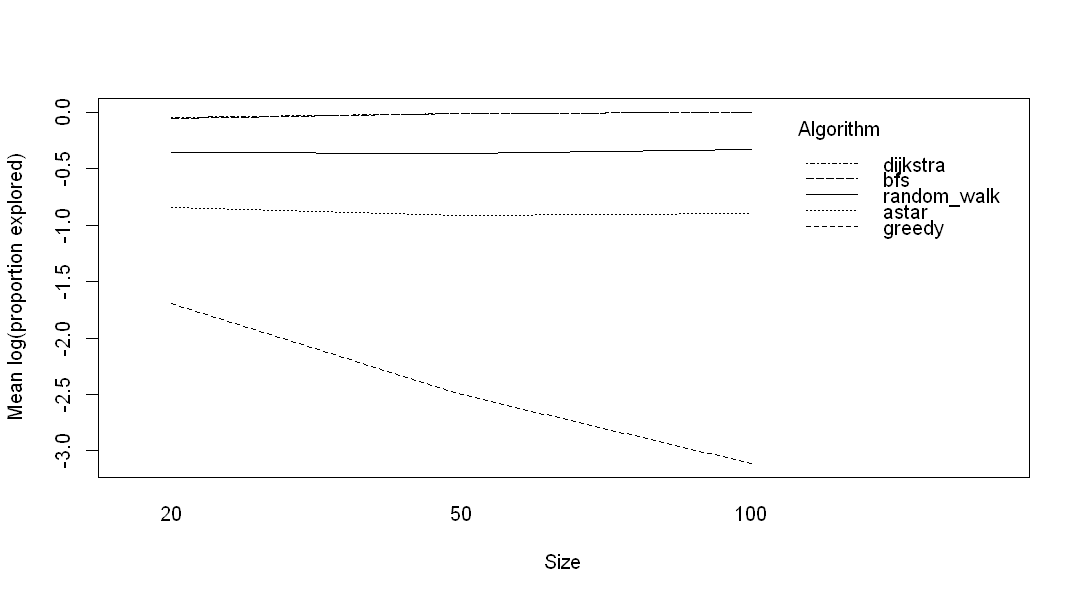

In [9]:
interaction.plot(dat$S, dat$A, dat$y, xlab = "Size", ylab = "Mean log(proportion explored)", trace.label = "Algorithm")

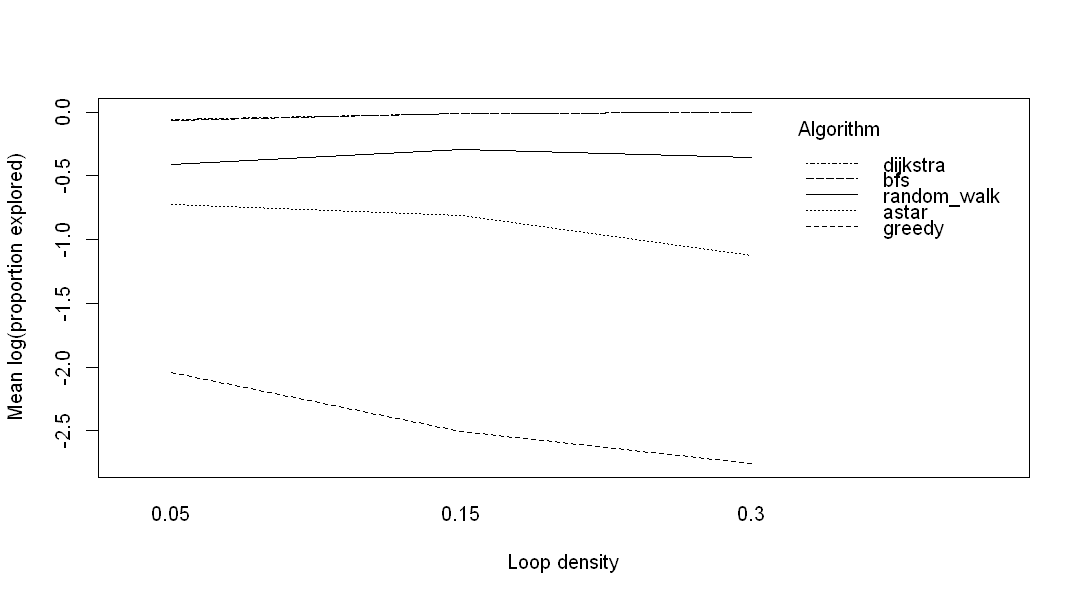

In [10]:
interaction.plot(dat$D, dat$A, dat$y, xlab = "Loop density", ylab = "Mean log(proportion explored)", trace.label = "Algorithm")

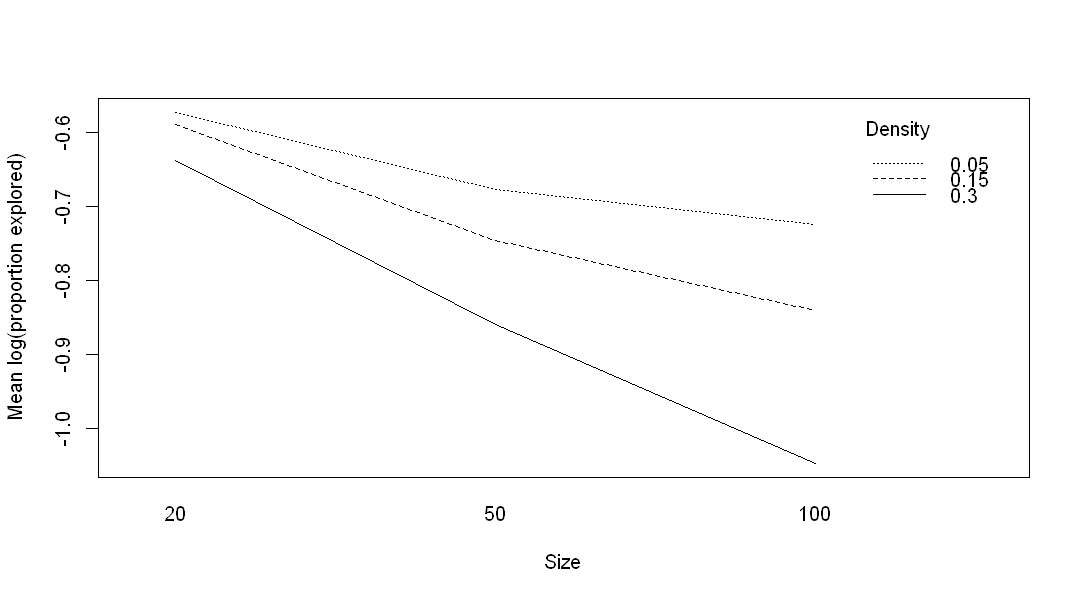

In [11]:
interaction.plot(dat$S, dat$D, dat$y, xlab = "Size", ylab = "Mean log(proportion explored)", trace.label = "Density")

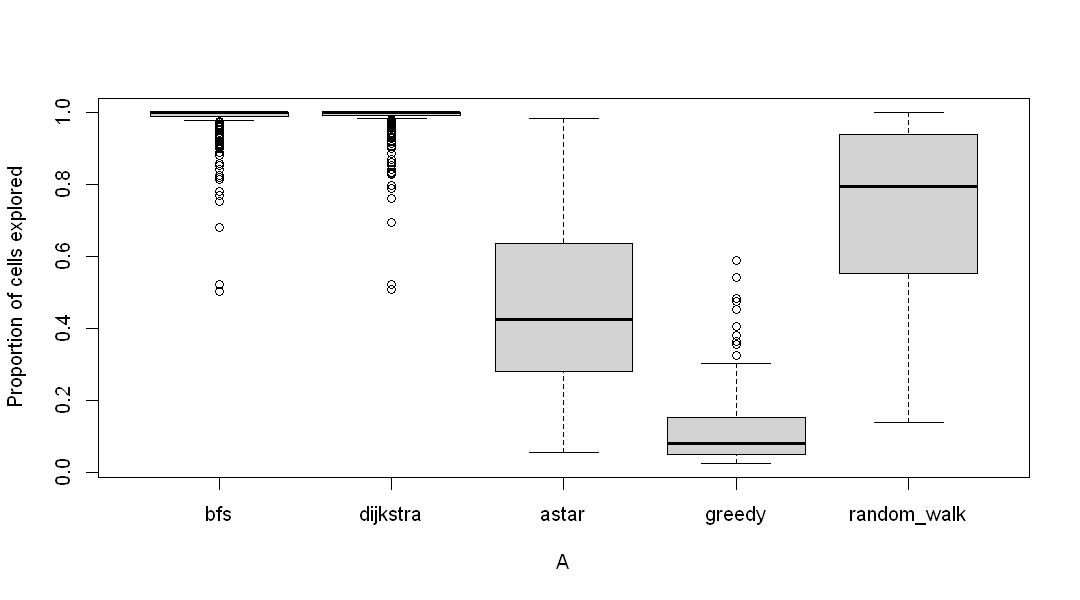

In [12]:
boxplot(frac_explored ~ A, data = dat, ylab = "Proportion of cells explored")

## 3. Algorithm comparisons

Algorithm comparisons use only within-maze differences, so they are tested against the subplot error. Fitting with maze as a block gives the same error term.

In [14]:
fit_w <- lm(y ~ maze + A*(S + D), data = dat)
emm <- emmeans(fit_w, ~ A, nuisance = "maze")

NOTE: Results may be misleading due to involvement in interactions



### Planned contrasts

Level order: bfs, dijkstra, astar, greedy, random_walk. BFS and Dijkstra are expected to be nearly identical on this unit-cost grid.

In [15]:
contrast(emm, method = list(
  "A* vs Dijkstra"          = c(0, -1, 1, 0, 0),
  "informed vs uninformed"  = c(-1/2, -1/2, 1/2, 1/2, 0),
  "random walk vs the rest" = c(-1/4, -1/4, -1/4, -1/4, 1)
))

 contrast                estimate     SE   df t.ratio p.value
 A* vs Dijkstra            -0.864 0.0247 1060 -35.032 <0.0001
 informed vs uninformed    -1.637 0.0174 1060 -93.880 <0.0001
 random walk vs the rest    0.488 0.0195 1060  25.057 <0.0001

Results are averaged over the levels of: 1 nuisance factors, S, D 

### Tukey multiple comparisons

Overall, and within each size and density.

In [16]:
pairs(emm, adjust = "tukey")

 contrast               estimate     SE   df t.ratio p.value
 bfs - dijkstra         -0.00164 0.0247 1060  -0.066  1.0000
 bfs - astar             0.86216 0.0247 1060  34.965 <0.0001
 bfs - greedy            2.40989 0.0247 1060  97.735 <0.0001
 bfs - random_walk       0.32916 0.0247 1060  13.349 <0.0001
 dijkstra - astar        0.86379 0.0247 1060  35.032 <0.0001
 dijkstra - greedy       2.41153 0.0247 1060  97.801 <0.0001
 dijkstra - random_walk  0.33080 0.0247 1060  13.416 <0.0001
 astar - greedy          1.54773 0.0247 1060  62.769 <0.0001
 astar - random_walk    -0.53300 0.0247 1060 -21.616 <0.0001
 greedy - random_walk   -2.08073 0.0247 1060 -84.385 <0.0001

Results are averaged over the levels of: 1 nuisance factors, S, D 
P value adjustment: tukey method for comparing a family of 5 estimates 

In [17]:
pairs(emmeans(fit_w, ~ A | S, nuisance = "maze"), adjust = "tukey")

S = 20:
 contrast                estimate     SE   df t.ratio p.value
 bfs - dijkstra         -0.004022 0.0427 1060  -0.094  1.0000
 bfs - astar             0.790320 0.0427 1060  18.505 <0.0001
 bfs - greedy            1.635239 0.0427 1060  38.289 <0.0001
 bfs - random_walk       0.304967 0.0427 1060   7.141 <0.0001
 dijkstra - astar        0.794342 0.0427 1060  18.599 <0.0001
 dijkstra - greedy       1.639261 0.0427 1060  38.383 <0.0001
 dijkstra - random_walk  0.308989 0.0427 1060   7.235 <0.0001
 astar - greedy          0.844919 0.0427 1060  19.784 <0.0001
 astar - random_walk    -0.485353 0.0427 1060 -11.364 <0.0001
 greedy - random_walk   -1.330272 0.0427 1060 -31.148 <0.0001

S = 50:
 contrast                estimate     SE   df t.ratio p.value
 bfs - dijkstra         -0.000733 0.0427 1060  -0.017  1.0000
 bfs - astar             0.897471 0.0427 1060  21.014 <0.0001
 bfs - greedy            2.486467 0.0427 1060  58.220 <0.0001
 bfs - random_walk       0.350987 0.0427 1060   8.218

In [18]:
pairs(emmeans(fit_w, ~ A | D, nuisance = "maze"), adjust = "tukey")

D = 0.05:
 contrast                estimate     SE   df t.ratio p.value
 bfs - dijkstra         -0.003744 0.0427 1060  -0.088  1.0000
 bfs - astar             0.658209 0.0427 1060  15.412 <0.0001
 bfs - greedy            1.976666 0.0427 1060  46.283 <0.0001
 bfs - random_walk       0.344114 0.0427 1060   8.057 <0.0001
 dijkstra - astar        0.661953 0.0427 1060  15.499 <0.0001
 dijkstra - greedy       1.980411 0.0427 1060  46.371 <0.0001
 dijkstra - random_walk  0.347859 0.0427 1060   8.145 <0.0001
 astar - greedy          1.318458 0.0427 1060  30.871 <0.0001
 astar - random_walk    -0.314094 0.0427 1060  -7.354 <0.0001
 greedy - random_walk   -1.632552 0.0427 1060 -38.226 <0.0001

D = 0.15:
 contrast                estimate     SE   df t.ratio p.value
 bfs - dijkstra         -0.000632 0.0427 1060  -0.015  1.0000
 bfs - astar             0.805142 0.0427 1060  18.852 <0.0001
 bfs - greedy            2.499606 0.0427 1060  58.528 <0.0001
 bfs - random_walk       0.287185 0.0427 1060   6

## 4. Diagnostics

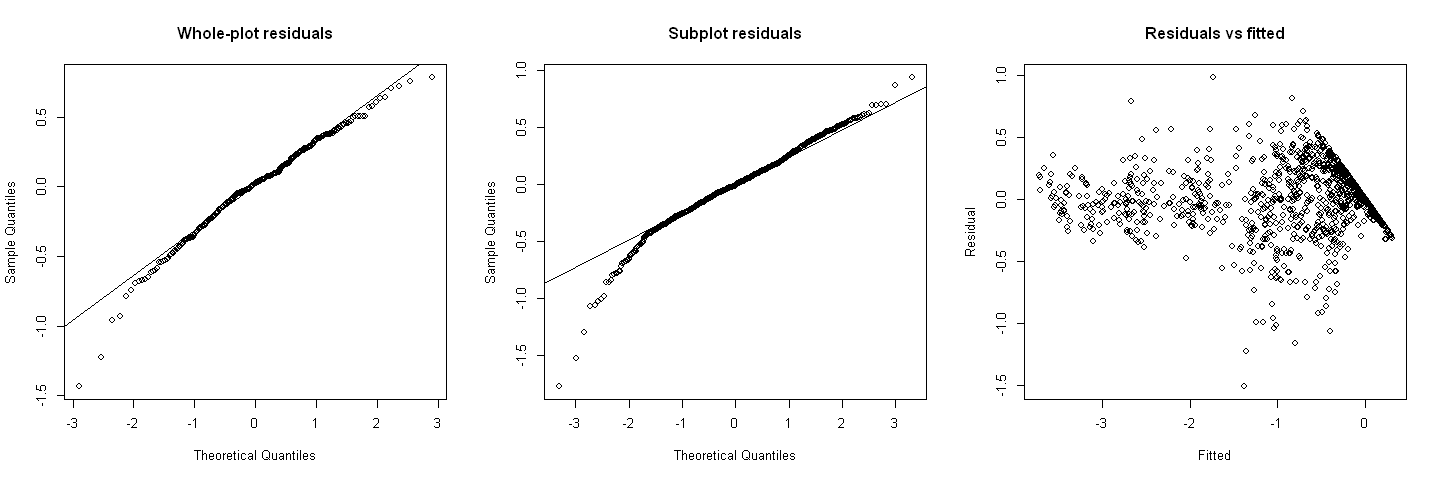

In [19]:
options(repr.plot.width = 12, repr.plot.height = 4)
par(mfrow = c(1, 3))
qqnorm(resid(fit[["maze"]]),   main = "Whole-plot residuals"); qqline(resid(fit[["maze"]]))
qqnorm(resid(fit[["Within"]]), main = "Subplot residuals");    qqline(resid(fit[["Within"]]))
plot(fitted(fit_w), resid(fit_w), xlab = "Fitted", ylab = "Residual",
     main = "Residuals vs fitted")
par(mfrow = c(1, 1))
options(repr.plot.width = 9, repr.plot.height = 5)

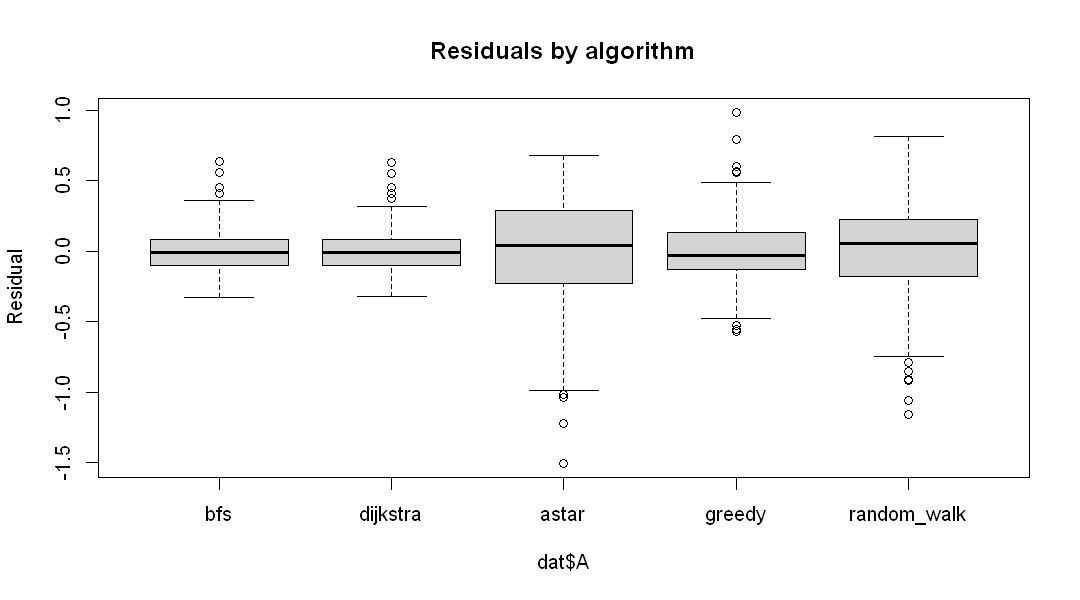

In [20]:
boxplot(resid(fit_w) ~ dat$A, ylab = "Residual", main = "Residuals by algorithm")

### Is the log transformation enough?

Look for a Box-Cox lambda near 0.

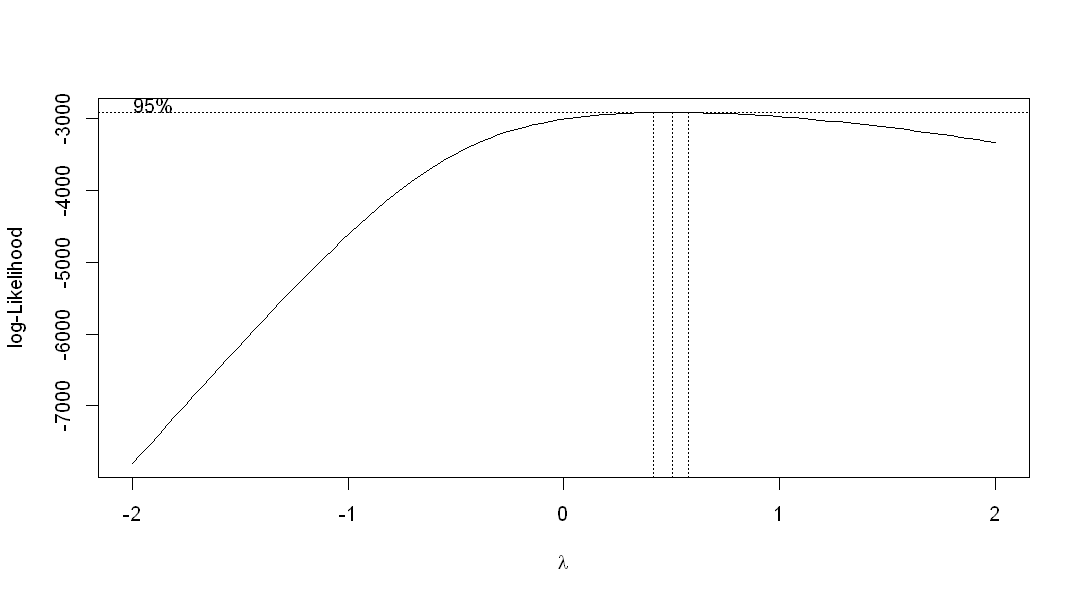

In [21]:
boxcox(lm(frac_explored ~ maze + A*(S + D), data = dat))

## 5. Sensitivity check

Refit without random walk, since its runs can be capped.

In [22]:
dat5 <- droplevels(dat[dat$A != "random_walk", ])
summary(aov(y ~ G + S*D + A*(S + D) + Error(maze), data = dat5))


Error: maze
           Df Sum Sq Mean Sq F value   Pr(>F)    
G           2  3.737   1.868  17.551 7.11e-08 ***
S           2 21.540  10.770 101.167  < 2e-16 ***
D           2 11.274   5.637  52.950  < 2e-16 ***
S:D         4  2.753   0.688   6.466 5.66e-05 ***
Residuals 259 27.573   0.106                     
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Error: Within
           Df Sum Sq Mean Sq F value Pr(>F)    
A           3 1046.8   348.9 5006.85 <2e-16 ***
S:A         6   70.4    11.7  168.37 <2e-16 ***
D:A         6   20.9     3.5   50.05 <2e-16 ***
Residuals 795   55.4     0.1                   
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1